In [1]:
import os
import random
import ssl

import certifi
import kagglehub
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("charlesaverill/gothic-literature")

print("Path to dataset files:", path)

100%|██████████| 1.61M/1.61M [00:00<00:00, 10.6MB/s]

Extracting files...
Path to dataset files: /Users/christinalapane/.cache/kagglehub/datasets/charlesaverill/gothic-literature/versions/3


In [3]:
# Combine all the downloaded .txt files into one dataset
txt_files = sorted(f for f in os.listdir(path) if f.endswith(".txt"))

records = []
for fname in txt_files:
    with open(os.path.join(path, fname), encoding="utf-8", errors="ignore") as f:
        records.append({"book": fname.removesuffix(".txt"), "text": f.read()})

# One row per book (handy if you want to know which book a word came from)
books_df = pd.DataFrame(records)
books_df["n_chars"] = books_df["text"].str.len()
books_df["n_words"] = books_df["text"].str.split().str.len()

# One big string with every book joined together
corpus = "\n\n".join(books_df["text"])

print(f"Combined {len(books_df)} books -> {len(corpus):,} characters, {len(corpus.split()):,} words")
books_df[["book", "n_chars", "n_words"]]

Combined 8 books -> 4,182,104 characters, 760,523 words


,book,n_chars,n_words
0,castleofotranto,211408,36562
1,doriangray,431489,78543
2,dracula,842174,160814
3,drjekyllmrhyde,138456,25572
4,frankenstein,420643,74975
5,janeeyre,1024423,184516
6,phantomoftheopera,463739,83644
7,wutheringheights,649758,115897


In [5]:
books_df.head()

,book,text,n_chars,n_words
0,castleofotranto,INTRODUCTION\n\n\nHORACE WALPOLE was the young...,211408,36562
1,doriangray,CHAPTER 1\n\nThe studio was filled with the ri...,431489,78543
2,dracula,CHAPTER I\n\nJONATHAN HARKER'S JOURNAL\n\n(_Ke...,842174,160814
3,drjekyllmrhyde,STORY OF THE DOOR\n\nMr. Utterson the lawyer w...,138456,25572
4,frankenstein,"Letter 1\n\n_To Mrs. Saville, England._\n\n\nS...",420643,74975


## 1. Normalizing the sample sentences

Raw novel text has capital letters, curly quotes, accented letters, punctuation, chapter headings and very common function words ("the", "of", "and"). None of these should count as separate words when we look at a word's neighbours, so the text is normalized first.

**Pseudocode**

```
function NORMALIZE(text, remove_stopwords):
    text ← Unicode-decompose text, drop accent marks          # "café" → "cafe"
    text ← replace curly quotes with straight quotes          # "don’t" → "don't"
    delete lines that are only a heading ("CHAPTER XII", "THE END")
    text ← lowercase(text)                                    # "Night" = "night"
    remove the period after titles (mr., mrs., dr., ...)      # so "Mr. Hyde" is not split
    sentences ← split text on . ! ?
    for each sentence s:
        tokens ← every match of  [a-z]+('[a-z]+)*  in s       # words only; punctuation and digits are dropped
        if remove_stopwords: drop tokens in the NLTK English stopword list
        if tokens is not empty: add tokens to the output
    return the list of sentences (each a list of tokens)
```

The output keeps the sentence boundaries. Step 2 uses them so that a context window never crosses from one sentence into the next.

In [6]:
import re
import unicodedata
from collections import Counter

# fix the macOS certificate error so NLTK downloads work
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

STOPWORDS = set(stopwords.words("english"))
ABBREVIATIONS = ["mr.", "mrs.", "dr.", "st.", "mme.", "mlle."]
HEADING = re.compile(r"^\s*(?:(?:CHAPTER|LETTER)\s+[IVXLC\d]+\.?|THE END)\s*$", re.MULTILINE)
SENTENCE_END = re.compile(r"[.!?]+")
WORD = re.compile(r"[a-z]+(?:'[a-z]+)*")


def normalize(text, remove_stopwords=True):
    """Turn raw text into a list of sentences, each a list of clean lower-case word tokens."""
    # accented letters -> plain letters (é -> e), curly quotes -> straight quotes
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    text = text.replace("‘", "'").replace("’", "'").replace("“", '"').replace("”", '"')

    # drop lines that are only a heading (checked before lower-casing, while headings are still in capitals)
    text = HEADING.sub(" ", text)

    text = text.lower()

    # "mr. hyde" -> "mr hyde", so the title's period isn't read as the end of a sentence
    for abbr in ABBREVIATIONS:
        text = re.sub(rf"\b{re.escape(abbr)}", abbr[:-1], text)

    sentences = []
    for chunk in SENTENCE_END.split(text):
        tokens = WORD.findall(chunk)
        if remove_stopwords:
            tokens = [t for t in tokens if t not in STOPWORDS]
        if tokens:
            sentences.append(tokens)
    return sentences


# small sample sentences, so every step can be checked by hand
samples = [
    "The cold, dark NIGHT fell over the castle.",
    "Mr. Harker walked through the dark night alone!",
    "A cold wind blew across the moor at night; the castle was silent.",
    "By day the castle looked bright and the wind was warm.",
]
sample_sentences = normalize("\n".join(samples))
for raw, clean in zip(samples, sample_sentences):
    print(f"{raw!r:70} -> {clean}")

'The cold, dark NIGHT fell over the castle.'                           -> ['cold', 'dark', 'night', 'fell', 'castle']
'Mr. Harker walked through the dark night alone!'                      -> ['mr', 'harker', 'walked', 'dark', 'night', 'alone']
'A cold wind blew across the moor at night; the castle was silent.'    -> ['cold', 'wind', 'blew', 'across', 'moor', 'night', 'castle', 'silent']
'By day the castle looked bright and the wind was warm.'               -> ['day', 'castle', 'looked', 'bright', 'wind', 'warm']


In [7]:
# normalize the whole gothic corpus
sentences = normalize(corpus)
n_tokens = sum(len(s) for s in sentences)
print(f"{len(sentences):,} sentences, {n_tokens:,} tokens after normalization, "
      f"{len({t for s in sentences for t in s}):,} distinct words")
print(sentences[:3])

44,527 sentences, 355,052 tokens after normalization, 23,248 distinct words
[['introduction', 'horace', 'walpole', 'youngest', 'son', 'sir', 'robert', 'walpole', 'great', 'statesman', 'died', 'earl', 'orford'], ['born', 'year', 'father', 'resigned', 'office', 'remaining', 'opposition', 'almost', 'three', 'years', 'return', 'long', 'tenure', 'power'], ['horace', 'walpole', 'educated', 'eton', 'formed', 'school', 'friendship', 'thomas', 'gray', 'months', 'older']]


## 2. Extracting the words within distance d of x

The context of a word $x$ is every word that appears at most $d$ positions to its left or right, inside the same sentence. Distance is counted on the normalized tokens, so with stopwords removed, $d$ means "$d$ content words away".

**Pseudocode**

```
function CONTEXT_WORDS(sentences, x, d):
    counts ← empty map  word → count
    for each sentence tokens[0 .. n-1] in sentences:
        for i from 0 to n-1:
            if tokens[i] = x:
                window ← tokens[max(0, i-d) .. i-1]  ++  tokens[i+1 .. min(n-1, i+d)]
                for each word w in window: counts[w] ← counts[w] + 1
    return counts
```

To turn the counts into a vector, fix a vocabulary $V = (w_1, \dots, w_{|V|})$. The vector for $x$ is then $\mathbf{v}_x = (\text{count}(x, w_1), \dots, \text{count}(x, w_{|V|}))$: one row of the word–context co-occurrence matrix.

In [8]:
def context_words(sentences, x, d):
    """Count every word that appears within d tokens of x (same sentence, x itself excluded)."""
    counts = Counter()
    for tokens in sentences:
        for i, tok in enumerate(tokens):
            if tok == x:
                left = tokens[max(0, i - d):i]   # max(0, ...) stops a negative index wrapping to the end
                right = tokens[i + 1:i + 1 + d]  # slicing past the end just stops at the end
                counts.update(left + right)
    return counts


def to_vector(counts, vocab):
    """Turn a context Counter into a count vector, in the order of vocab."""
    return np.array([counts.get(w, 0) for w in vocab])


print("contexts of 'night' with d=2:", dict(context_words(sample_sentences, "night", d=2)))
print("contexts of 'day'   with d=2:", dict(context_words(sample_sentences, "day", d=2)))

contexts of 'night' with d=2: {'cold': 1, 'dark': 2, 'fell': 1, 'castle': 2, 'walked': 1, 'alone': 1, 'across': 1, 'moor': 1, 'silent': 1}
contexts of 'day'   with d=2: {'castle': 1, 'looked': 1}


## 3. Why the code works

**Normalization.** Each step removes one kind of surface variation that would otherwise split one word into several:

* **Unicode decomposition and quote mapping.** `é` is stored as `e` plus a separate accent mark. Dropping the mark makes "café" and "cafe" the same token, and mapping curly quotes means "don’t" (Frankenstein uses curly quotes) and "don't" match.
* **Lower-casing.** Makes "Night" at the start of a sentence equal to "night" in the middle.
* **Heading removal.** Runs before lower-casing and only matches a line that is *entirely* a heading, such as `CHAPTER XII`. That way prose lines like "the end was near." are kept. A looser filter would delete them.
* **Abbreviations.** "Mr. Hyde" would otherwise be split into two sentences at the period, separating "mr" from "hyde".
* **Tokenization.** `[a-z]+('[a-z]+)*` matches runs of letters, optionally joined by apostrophes. Punctuation, dashes ("--") and numbers never match, so they cannot become context words, while contractions like "don't" stay as one token.
* **Stopword removal.** Function words like "the" appear next to almost every noun, so they say little about meaning and would dominate every vector. After removing them, the window holds content words.

**Context extraction.** For an occurrence of $x$ at position $i$, the code takes exactly the tokens at positions $i-d, \dots, i-1$ and $i+1, \dots, i+d$ that exist:

* `tokens[max(0, i-d):i]` covers the left side. The `max(0, …)` matters because a negative start index in Python counts from the *end* of the list, which would pull in words from the far end of the sentence.
* `tokens[i+1:i+1+d]` covers the right side. Python slices stop quietly at the end of the list, so an $x$ near the end of a sentence just gets a shorter window.
* Position $i$ itself is never included, so $x$ is not counted as its own context. Another copy of $x$ *inside* the window is counted, which matches the definition ("the words that appear near $x$").
* Every occurrence of $x$ in every sentence is visited, and `Counter.update` adds one per window position. The final count for $w$ is therefore exactly the number of (occurrence of $x$, nearby $w$) pairs.
* Windows are built per sentence, so they never cross a sentence boundary.

The cell below checks these claims with small hand-made cases, including the edge cases.

In [9]:
# x in the middle: d=2 takes two words each side and stops there
assert context_words([["a", "b", "x", "c", "d", "e"]], "x", 2) == Counter(a=1, b=1, c=1, d=1)
# x at the start or end: shorter window, and no wrap-around to the other end
assert context_words([["x", "a", "b", "c"]], "x", 2) == Counter(a=1, b=1)
assert context_words([["a", "x", "b", "c", "d"]], "x", 3) == Counter(a=1, b=1, c=1, d=1)
assert context_words([["a", "b", "c", "x"]], "x", 2) == Counter(b=1, c=1)
# x repeated: every occurrence counts, and the other x counts as context
assert context_words([["x", "a", "x"]], "x", 2) == Counter(a=2, x=2)
# windows never cross sentence boundaries
assert context_words([["a", "x"], ["b", "c"]], "x", 2) == Counter(a=1)
# word not present -> empty context
assert context_words([["a", "b"]], "x", 2) == Counter()

# normalization: accents, curly quotes, titles, headings, punctuation, digits, case
assert normalize("Café “Don’t” go, Mr. Hyde!\nCHAPTER IV\nHe ran 3 miles.", remove_stopwords=False) == [
    ["cafe", "don't", "go", "mr", "hyde"], ["he", "ran", "miles"]]
# a prose line that only starts like a heading is kept
assert normalize("The end was near.", remove_stopwords=False) == [["the", "end", "was", "near"]]
print("all checks passed")

all checks passed


## 4. Example: representing a word as a vector

**Small example (checkable by hand).** After normalization, the four sample sentences are:

1. `cold dark night fell castle`
2. `mr harker walked dark night alone`
3. `cold wind blew across moor night castle silent`
4. `day castle looked bright wind warm`

With $d = 2$, "night" occurs three times:

* sentence 1: {cold, dark} on the left, {fell, castle} on the right
* sentence 2: {walked, dark} on the left, {alone} on the right (end of sentence)
* sentence 3: {across, moor} on the left, {castle, silent} on the right

So *dark* = 2, *castle* = 2, and every other neighbour = 1. The table below lays these counts out over the full sample vocabulary. That row is the vector for "night".

In [10]:
d = 2
sample_vocab = sorted({t for s in sample_sentences for t in s})

sample_vectors = pd.DataFrame(
    [to_vector(context_words(sample_sentences, w, d), sample_vocab) for w in ["night", "day"]],
    index=["night", "day"], columns=sample_vocab,
)
sample_vectors

,across,alone,blew,bright,castle,cold,dark,day,fell,harker,looked,moor,mr,night,silent,walked,warm,wind
night,1,1,0,0,2,1,2,0,1,0,0,1,0,0,1,1,0,0
day,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0


**Full corpus example.** On the gothic novels, the vocabulary is the 5,000 most frequent words after normalization and the window is $d = 4$. Each word becomes a 5,000-dimensional count vector. Below are the largest entries of the vector for "night".

'night' occurs 959 times; vector length 5,000, 1,703 non-zero entries
last       108
day         58
shall       53
good        48
night       44
one         38
said        37
must        33
sleep       32
go          30
well        28
morning     28
come        28
came        27
may         25


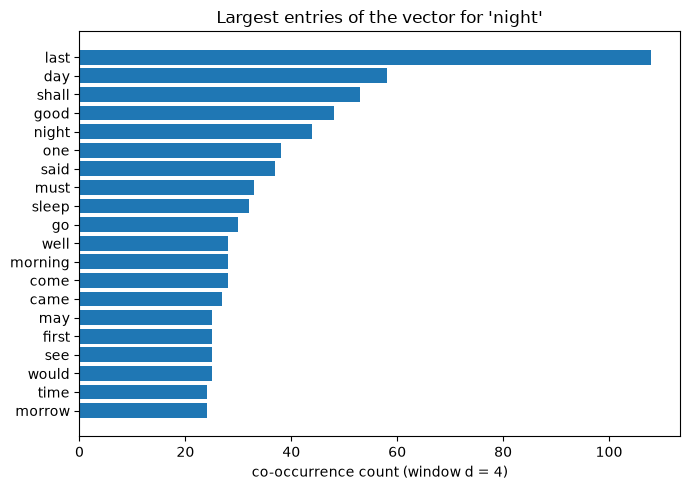

In [11]:
D = 4
VOCAB_SIZE = 5000
word_freq = Counter(t for s in sentences for t in s)
vocab = [w for w, _ in word_freq.most_common(VOCAB_SIZE)]

night_vec = to_vector(context_words(sentences, "night", D), vocab)
print(f"'night' occurs {word_freq['night']:,} times; vector length {len(night_vec):,}, "
      f"{(night_vec > 0).sum():,} non-zero entries")

night_series = pd.Series(night_vec, index=vocab).sort_values(ascending=False)
print(night_series.head(15).to_string())

top = night_series.head(20)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values)
plt.xlabel(f"co-occurrence count (window d = {D})")
plt.title("Largest entries of the vector for 'night'")
plt.tight_layout()
plt.show()

**Do similar contexts mean similar meanings?** If the distributional hypothesis holds, words with related meanings should have similar context vectors. Cosine similarity, $\cos(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert}$, compares the direction of two vectors, so a frequent word and a rare word can still score as similar.

In [12]:
def cosine(u, v):
    return u @ v / (np.linalg.norm(u) * np.linalg.norm(v))

words = ["night", "evening", "morning", "day", "love", "heart", "knife", "sword"]
vectors = {w: to_vector(context_words(sentences, w, D), vocab) for w in words}
similarity = pd.DataFrame([[cosine(vectors[a], vectors[b]) for b in words] for a in words],
                          index=words, columns=words)
similarity.round(2)

,night,evening,morning,day,love,heart,knife,sword
night,1.00,0.63,0.63,0.71,0.46,0.49,0.22,0.11
evening,0.63,1.00,0.63,0.69,0.41,0.39,0.22,0.09
morning,0.63,0.63,1.00,0.74,0.41,0.45,0.23,0.10
day,0.71,0.69,0.74,1.00,0.52,0.52,0.24,0.11
love,0.46,0.41,0.41,0.52,1.00,0.66,0.23,0.13
heart,0.49,0.39,0.45,0.52,0.66,1.00,0.31,0.16
knife,0.22,0.22,0.23,0.24,0.23,0.31,1.00,0.08
sword,0.11,0.09,0.10,0.11,0.13,0.16,0.08,1.00


**Reading the results.** The four time-of-day words score 0.63–0.74 with each other: they appear in similar frames ("last night", "next morning", "all day"). *love* and *heart* score 0.66, and both are far from the weapons. This matches the distributional hypothesis.

The low scores for *knife* and *sword* show a limit of raw counts. *sword* occurs only 13 times and *knife* 52, so their vectors are short and sparse and share few context words with anything. Raw counts also favour frequent words ("last", "shall", "said" are among the top neighbours of "night"). The usual fixes are reweighting the counts with PPMI or TF-IDF, a larger corpus, or dense embeddings (word2vec, GloVe) trained on the same idea.